# TLT — mean reversion vs momentum (daily bars)

The question: **does TLT behave more like a trending or a mean-reverting asset, and can either
rule beat simply holding it?**

1. **Diagnostics** on the train period — autocorrelation, variance ratio, Hurst exponent, ADF, half-life
2. **Two long/cash strategies**, both using Yi-Kai's modules in `AlgoGoneCrazy/src/trading_strategy`
   (`generate_momentum_signals`, `generate_mean_reversion_signals`), unchanged
3. **Parameter search** on train → shortlist → pick on validation → **test touched once**
4. Results against TLT buy & hold (same engine, costs and metrics as
   `benchmark_buy_and_hold_all_assets.ipynb`)

Execution rule (no look-ahead): a signal is known at the day's close and is traded at the **next
day's open**. Costs: IBKR Pro Tiered (USD 0.0035/share, min 0.35) + 2 bps slippage per order.

## 0. Setup

In [1]:
import os
import sys
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


def find_repo_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "AlgoGoneCrazy-dev-trade-tracker").is_dir():
            return p
    raise FileNotFoundError("Could not find AlgoGoneCrazy-dev-trade-tracker above " + str(start))


REPO_ROOT = find_repo_root()
TRACKER_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-trade-tracker"     # Suppanat: backtest engine + metrics
STRATEGY_SRC = REPO_ROOT / "AlgoGoneCrazy" / "src"              # Yi-Kai: momentum / mean-reversion rules
MODEL_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-model" / "model"
RESULTS_DIR = MODEL_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

for p in (TRACKER_DIR, STRATEGY_SRC):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from src.backtest import run_backtest
from src.tracker import CostModel
from src.metrics import compute_metrics, drawdown_series
from trading_strategy import (MomentumParameters, MeanReversionParameters,
                              generate_momentum_signals, generate_mean_reversion_signals)

print("repo root:", REPO_ROOT)

repo root: /home/claude/work/Githubrepo


## 1. Settings

In [2]:
INITIAL_CASH = 100_000.0
SLIPPAGE_BPS = 2.0
PER_SHARE, MIN_FEE, CAP_PCT = 0.0035, 0.35, 0.01      # IBKR Pro Tiered (cost_assumptions.json)
PPY = 252                                             # trading days per year

# same split as the BTC notebooks and the benchmark notebook
TRAIN_END = "2025-10-22"
VAL_END = "2026-04-05"

MIN_TRADES_TRAIN = 5        # ignore parameter sets that barely trade on train
SHORTLIST = 10              # best-N on train go forward to validation

MOM_GRID = {"fast_window": [5, 10, 20], "slow_window": [40, 60, 100, 150],
            "momentum_lookback": [20, 60, 120]}
MR_GRID = {"window": [10, 20, 40, 60], "entry_z_score": [-1.0, -1.5, -2.0],
           "exit_z_score": [-0.5, 0.0, 0.5], "maximum_holding_bars": [10, 20, None]}
TAG = "tlt"

## 2. Load TLT daily bars

Team 30-min file (newest OneDrive snapshot) → one bar per session, dividend-adjusted.
Same construction as the benchmark notebook.

In [3]:
DATA_DIR = None   # set a full path to override


def find_data_dir() -> Path:
    if DATA_DIR:
        return Path(DATA_DIR)
    if os.environ.get("FE5209_DATA_DIR"):
        return Path(os.environ["FE5209_DATA_DIR"])
    for base in (Path.home() / "National University of Singapore", REPO_ROOT.parent, REPO_ROOT):
        if base.is_dir():
            hits = sorted(base.glob("*FE5209_Group_Project/data"))
            if hits:
                return hits[0]
    raise FileNotFoundError("Team data folder not found - set DATA_DIR")


data_dir = find_data_dir()
latest = sorted(p for p in data_dir.iterdir() if p.is_dir() and p.name.isdigit())[-1]
raw = pd.read_csv(latest / "canonical" / "market_bars_30m.csv", low_memory=False,
                  usecols=["source_symbol", "bar_open_time_utc", "session_date_local", "open", "high",
                           "low", "close", "adjusted_close", "volume"])
raw = raw[raw["source_symbol"] == "TLT"].sort_values("bar_open_time_utc")
f = raw["adjusted_close"] / raw["close"]
for c in ("open", "high", "low", "close"):
    raw[c] = raw[c] * f
g = raw.groupby("session_date_local")
tlt = pd.DataFrame({"open": g["open"].first(), "high": g["high"].max(), "low": g["low"].min(),
                    "close": g["close"].last(), "volume": g["volume"].sum()})
tlt.index = pd.DatetimeIndex(pd.to_datetime(tlt.index), name="date")

periods = {"train": (None, TRAIN_END),
           "val": (pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1), VAL_END),
           "test": (pd.Timestamp(VAL_END) + pd.Timedelta(days=1), None),
           "full": (None, None)}
print("snapshot:", latest.name, "|", tlt.index.min().date(), "->", tlt.index.max().date(), "|", len(tlt), "days")
for k, (a, b) in periods.items():
    s = tlt.loc[a:b]
    print(f"{k:5s} {s.index.min().date()} -> {s.index.max().date()}  ({len(s)} days)")

snapshot: 260918 | 2023-09-18 -> 2026-09-16 | 752 days
train 2023-09-18 -> 2025-10-22  (527 days)
val   2025-10-23 -> 2026-04-02  (111 days)
test  2026-04-06 -> 2026-09-16  (114 days)
full  2023-09-18 -> 2026-09-16  (752 days)


## 3. Diagnostics — trending or mean-reverting? (train period only)

| Test | Trending if | Mean-reverting if |
|---|---|---|
| Return autocorrelation (lag 1–5) | > 0 | < 0 |
| Variance ratio VR(q) | > 1 | < 1 |
| Hurst exponent | > 0.5 | < 0.5 |
| ADF on log price | can't reject unit root | rejects unit root (t < −2.86) |
| Half-life (AR(1) on log price) | very long / negative | short, finite |

Only train data is used here, so the diagnostics can't leak information from validation or test.

In [4]:
def variance_ratio(logp: pd.Series, q: int) -> tuple[float, float]:
    # Lo-MacKinlay VR(q) with the homoskedastic z-statistic.
    r = logp.diff().dropna().to_numpy()
    n = len(r)
    mu = r.mean()
    var1 = ((r - mu) ** 2).sum() / (n - 1)
    rq = logp.diff(q).dropna().to_numpy()
    varq = ((rq - q * mu) ** 2).sum() / (q * (n - q + 1) * (1 - q / n))
    vr = varq / var1
    z = (vr - 1) / np.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q * n))
    return vr, z


def hurst(logp: pd.Series, max_lag: int = 100) -> float:
    # Slope of log std(p[t+lag] - p[t]) on log lag; 0.5 = random walk.
    lags = np.arange(2, max_lag)
    tau = [np.std(logp.diff(l).dropna()) for l in lags]
    return float(np.polyfit(np.log(lags), np.log(tau), 1)[0])


def adf_t(logp: pd.Series, lags: int = 1) -> float:
    # ADF t-stat with constant: dp_t = a + b p_{t-1} + sum c_i dp_{t-i}. 5% critical value = -2.86.
    p = logp.to_numpy()
    dp = np.diff(p)
    y = dp[lags:]
    X = [np.ones_like(y), p[lags:-1]] + [dp[lags - i:-i] for i in range(1, lags + 1)]
    X = np.column_stack(X)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    s2 = resid @ resid / (len(y) - X.shape[1])
    se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
    return float(beta[1] / se)


def half_life(logp: pd.Series) -> float:
    dp = logp.diff().dropna()
    lag = logp.shift(1).loc[dp.index]
    b = np.polyfit(lag, dp, 1)[0]
    return float(-np.log(2) / b) if b < 0 else np.inf


def diagnostics(px: pd.Series) -> pd.Series:
    logp = np.log(px)
    r = logp.diff().dropna()
    out = {f"autocorr lag {k}": r.autocorr(k) for k in range(1, 6)}
    for q in (2, 5, 10, 20):
        vr, z = variance_ratio(logp, q)
        out[f"VR({q})"] = vr
        out[f"VR({q}) z"] = z
    out["Hurst"] = hurst(logp)
    out["ADF t-stat (5% crit -2.86)"] = adf_t(logp)
    out["half-life (days)"] = half_life(logp)
    return pd.Series(out)


diag = pd.DataFrame({"train": diagnostics(tlt.loc[:TRAIN_END, "close"]),
                     "full (reference)": diagnostics(tlt["close"])})
diag.round(3)

,train,full (reference)
autocorr lag 1,-0.010,-0.022
autocorr lag 2,-0.041,-0.044
autocorr lag 3,0.004,0.003
autocorr lag 4,0.027,0.021
autocorr lag 5,-0.084,-0.068
VR(2),0.993,0.980
VR(2) z,-0.149,-0.550
VR(5),0.956,0.927
VR(5) z,-0.457,-0.914
VR(10),0.917,0.883


In [5]:
d = diag["train"]
votes_mr = sum([d[[f"autocorr lag {k}" for k in range(1, 6)]].mean() < 0,
                d[["VR(2)", "VR(5)", "VR(10)", "VR(20)"]].mean() < 1,
                d["Hurst"] < 0.5,
                d["ADF t-stat (5% crit -2.86)"] < -2.86])
print(f"Mean-reversion votes: {votes_mr} / 4")
print(f"Half-life on train: {d['half-life (days)']:.0f} trading days")
print("Significant at 5% (|z| > 1.96):",
      [q for q in (2, 5, 10, 20) if abs(d[f'VR({q}) z']) > 1.96] or "none")

Mean-reversion votes: 3 / 4
Half-life on train: 28 trading days
Significant at 5% (|z| > 1.96): none


## 4. Strategy plumbing

* Yi-Kai's functions take a long-format frame (`instrument_id`, `bar_open_time_utc`, `adjusted_close`)
  and return `target_position` (0 or 1) per bar.
* Signals are computed on the **full history** so every period starts with warmed-up indicators,
  then **shifted one day** (known at close → traded next open) and backtested per period on the
  shared engine.

In [6]:
class TLTCost(CostModel):
    def apply(self, asset, qty, ref_price):
        direction = 1.0 if qty > 0 else -1.0
        exec_price = ref_price * (1 + direction * SLIPPAGE_BPS / 1e4)
        notional = abs(qty) * exec_price
        fee = min(max(abs(qty) * PER_SHARE, MIN_FEE), CAP_PCT * notional)
        return exec_price, fee, abs(qty) * abs(exec_price - ref_price)


COST = TLTCost()
strategy_input = pd.DataFrame({"instrument_id": "tlt", "bar_open_time_utc": tlt.index,
                               "adjusted_close": tlt["close"].to_numpy()})


def positions(kind: str, params: dict) -> pd.Series:
    if kind == "MOM":
        sig = generate_momentum_signals(strategy_input, MomentumParameters(**params))
    else:
        sig = generate_mean_reversion_signals(strategy_input, MeanReversionParameters(**params))
    target = pd.Series(sig["target_position"].to_numpy(dtype=float), index=tlt.index)
    return target.shift(1).fillna(0.0)          # trade at the next day's open


def backtest(pos: pd.Series, period: str):
    a, b = periods[period]
    return run_backtest(pos.loc[a:b], tlt.loc[a:b], asset="TLT", initial_cash=INITIAL_CASH,
                        cost_model=COST)


def metrics(res) -> pd.Series:
    eq = res.equity
    eq = pd.concat([pd.Series([INITIAL_CASH], index=[eq.index[0] - pd.Timedelta(days=1)]), eq])
    m = compute_metrics(eq, res.trades, res.positions, res.fills, periods_per_year=PPY)
    m["Average Holding Period (days)"] = m["Average Holding Period (hours)"] / 24
    return m


def label(kind, p):
    if kind == "MOM":
        return f"MOM (fast={p['fast_window']}, slow={p['slow_window']}, lb={p['momentum_lookback']})"
    return (f"MR (W={p['window']}, z={p['entry_z_score']}/{p['exit_z_score']}, "
            f"max={p['maximum_holding_bars']})")


buy_hold = pd.Series(1.0, index=tlt.index)

## 5. Parameter search — train only

Every combination is run on **train**; parameter sets with fewer than `MIN_TRADES_TRAIN` trades are
dropped. The top `SHORTLIST` by train Sharpe go to validation.

In [7]:
rows = []
cache = {}
for kind, grid in (("MOM", MOM_GRID), ("MR", MR_GRID)):
    keys = list(grid)
    for vals in product(*grid.values()):
        p = dict(zip(keys, vals))
        if kind == "MOM" and p["slow_window"] <= p["fast_window"]:
            continue
        pos = positions(kind, p)
        m = metrics(backtest(pos, "train"))
        cache[(kind, tuple(vals))] = pos
        rows.append({"kind": kind, "params": tuple(vals), "label": label(kind, p),
                     "train Sharpe": m["Sharpe Ratio"], "train Ann Return": m["Annual Return"],
                     "train Max DD": m["Max Drawdown"], "train Trades": m["Number of Trades"],
                     "train Exposure": m["Exposure (time in market)"]})
grid_df = pd.DataFrame(rows)
print(grid_df.groupby("kind").size().rename("combinations tried").to_string())
grid_df.sort_values("train Sharpe", ascending=False).groupby("kind").head(5) \
    .drop(columns="params").round(3)

kind
MOM     36
MR     108


,kind,label,train Sharpe,train Ann Return,train Max DD,train Trades,train Exposure
60,MR,"MR (W=10, z=-2.0/0.5, max=10)",1.684,0.103,-0.038,15.0,0.171
88,MR,"MR (W=20, z=-2.0/0.5, max=20)",1.487,0.099,-0.049,9.0,0.213
62,MR,"MR (W=10, z=-2.0/0.5, max=None)",1.481,0.093,-0.060,14.0,0.197
80,MR,"MR (W=20, z=-1.5/0.5, max=None)",1.351,0.117,-0.063,13.0,0.317
79,MR,"MR (W=20, z=-1.5/0.5, max=20)",1.348,0.115,-0.067,14.0,0.309
19,MOM,"MOM (fast=10, slow=100, lb=60)",0.288,0.020,-0.124,6.0,0.355
31,MOM,"MOM (fast=20, slow=100, lb=60)",0.221,0.014,-0.134,5.0,0.357
28,MOM,"MOM (fast=20, slow=60, lb=60)",0.105,0.005,-0.123,9.0,0.425
25,MOM,"MOM (fast=20, slow=40, lb=60)",0.064,0.002,-0.122,9.0,0.402
16,MOM,"MOM (fast=10, slow=60, lb=60)",0.056,0.001,-0.132,9.0,0.402


### Robustness check

If good results only appear for one lucky parameter set, it's probably noise. These heatmaps show
train Sharpe across the grid (averaging over the other parameters).

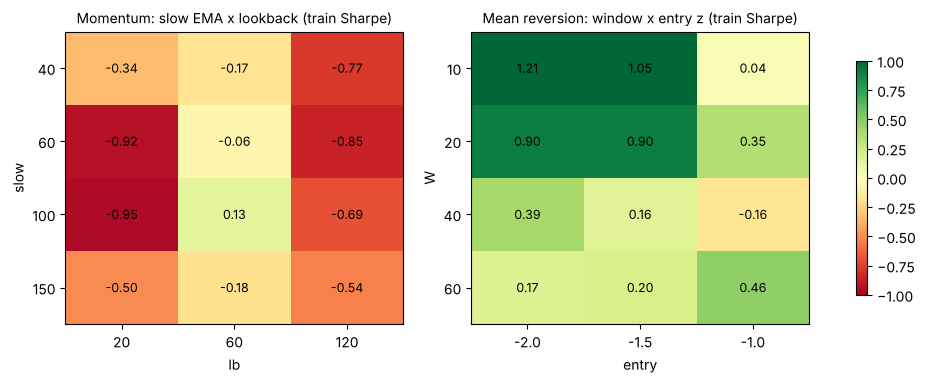

In [8]:
mom = grid_df[grid_df.kind == "MOM"].copy()
mom[["fast", "slow", "lb"]] = pd.DataFrame(mom["params"].tolist(), index=mom.index)
mr = grid_df[grid_df.kind == "MR"].copy()
mr[["W", "entry", "exit", "max"]] = pd.DataFrame(mr["params"].tolist(), index=mr.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (tab, title) in zip(axes, [
        (mom.pivot_table(index="slow", columns="lb", values="train Sharpe"), "Momentum: slow EMA x lookback"),
        (mr.pivot_table(index="W", columns="entry", values="train Sharpe"), "Mean reversion: window x entry z")]):
    im = ax.imshow(tab.values, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), tab.columns)
    ax.set_yticks(range(tab.shape[0]), tab.index)
    ax.set_xlabel(tab.columns.name)
    ax.set_ylabel(tab.index.name)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j, i, f"{tab.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(title + " (train Sharpe)", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(RESULTS_DIR / f"{TAG}_param_heatmaps.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Validation — pick one parameter set per strategy

From each strategy's train shortlist, keep the one with the best **validation** Sharpe.

In [9]:
shortlist = (grid_df[grid_df["train Trades"] >= MIN_TRADES_TRAIN]
             .sort_values("train Sharpe", ascending=False).groupby("kind").head(SHORTLIST).copy())
val_rows = []
for _, r in shortlist.iterrows():
    m = metrics(backtest(cache[(r.kind, r.params)], "val"))
    val_rows.append({"val Sharpe": m["Sharpe Ratio"], "val Ann Return": m["Annual Return"],
                     "val Max DD": m["Max Drawdown"], "val Trades": m["Number of Trades"]})
shortlist = pd.concat([shortlist.reset_index(drop=True), pd.DataFrame(val_rows)], axis=1)

chosen = shortlist.sort_values("val Sharpe", ascending=False).groupby("kind").head(1).set_index("kind")
shortlist.drop(columns="params").sort_values(["kind", "val Sharpe"], ascending=[True, False]).round(3)

,kind,label,train Sharpe,train Ann Return,train Max DD,train Trades,train Exposure,val Sharpe,val Ann Return,val Max DD,val Trades
18,MOM,"MOM (fast=20, slow=150, lb=20)",-0.151,-0.011,-0.102,11.0,0.216,-1.543,-0.090,-0.046,6.0
19,MOM,"MOM (fast=5, slow=150, lb=60)",-0.208,-0.017,-0.149,9.0,0.290,-1.848,-0.104,-0.059,5.0
14,MOM,"MOM (fast=10, slow=60, lb=60)",0.056,0.001,-0.132,9.0,0.402,-2.057,-0.113,-0.062,3.0
17,MOM,"MOM (fast=5, slow=100, lb=60)",-0.111,-0.011,-0.146,10.0,0.338,-2.057,-0.113,-0.062,3.0
10,MOM,"MOM (fast=10, slow=100, lb=60)",0.288,0.020,-0.124,6.0,0.355,-2.073,-0.116,-0.062,3.0
13,MOM,"MOM (fast=20, slow=40, lb=60)",0.064,0.002,-0.122,9.0,0.402,-2.073,-0.116,-0.062,3.0
11,MOM,"MOM (fast=20, slow=100, lb=60)",0.221,0.014,-0.134,5.0,0.357,-2.165,-0.126,-0.065,6.0
15,MOM,"MOM (fast=20, slow=150, lb=60)",-0.045,-0.006,-0.130,5.0,0.279,-2.165,-0.126,-0.065,6.0
12,MOM,"MOM (fast=20, slow=60, lb=60)",0.105,0.005,-0.123,9.0,0.425,-2.278,-0.132,-0.067,4.0
16,MOM,"MOM (fast=10, slow=40, lb=60)",-0.105,-0.013,-0.148,12.0,0.387,-2.543,-0.135,-0.072,4.0


In [10]:
print("Chosen:")
for kind, r in chosen.iterrows():
    print(f"  {kind:3s}: {r['label']}   train Sharpe {r['train Sharpe']:.2f} | val Sharpe {r['val Sharpe']:.2f}")

Chosen:
  MR : MR (W=20, z=-1.5/0.5, max=None)   train Sharpe 1.35 | val Sharpe 1.52
  MOM: MOM (fast=20, slow=150, lb=20)   train Sharpe -0.15 | val Sharpe -1.54


## 7. Test — run once, compare with buy & hold

Also shown: the before-cost return, so it's clear how much trading costs eat.

In [11]:
final = {"Buy & Hold": buy_hold}
for kind, r in chosen.iterrows():
    final[r["label"]] = cache[(kind, r["params"])]

res = {(name, p): backtest(pos, p) for name, pos in final.items() for p in ("train", "val", "test")}
table = pd.DataFrame({name: metrics(res[(name, "test")]) for name in final})

ROWS = ["Total Return", "Annual Return", "Annual Return (before costs)", "Annual Volatility",
        "Sharpe Ratio", "Sortino Ratio", "Max Drawdown", "Calmar Ratio", "Drawdown Count (>= 1%)",
        "Number of Trades", "Win Rate", "Average Holding Period (days)", "Profit per Trade",
        "Profit Factor", "Exposure (time in market)", "Total Transaction Cost"]
PCT = {"Total Return", "Annual Return", "Annual Return (before costs)", "Annual Volatility",
       "Max Drawdown", "Win Rate", "Exposure (time in market)"}
show = table.loc[ROWS].astype(object)
for r in ROWS:
    show.loc[r] = [f"{v:.1%}" if r in PCT else ("" if pd.isna(v) else f"{v:,.2f}") for v in table.loc[r]]
show

,Buy & Hold,"MR (W=20, z=-1.5/0.5, max=None)","MOM (fast=20, slow=150, lb=20)"
Total Return,-4.7%,-2.1%,-2.6%
Annual Return,-10.1%,-4.5%,-5.6%
Annual Return (before costs),-10.1%,-4.1%,-5.4%
Annual Volatility,8.9%,6.8%,2.6%
Sharpe Ratio,-1.16,-0.65,-2.19
Sortino Ratio,-1.55,-0.86,-2.24
Max Drawdown,-6.6%,-3.6%,-3.2%
Calmar Ratio,-1.54,-1.28,-1.74
Drawdown Count (>= 1%),2.00,1.00,1.00
Number of Trades,1.00,4.00,2.00


In [12]:
summary = pd.DataFrame({(name, p): metrics(res[(name, p)])[["Total Return", "Sharpe Ratio", "Max Drawdown",
                                                           "Number of Trades"]]
                        for name in final for p in ("train", "val", "test")}).T
summary.style.format({"Total Return": "{:.1%}", "Sharpe Ratio": "{:.2f}", "Max Drawdown": "{:.1%}",
                      "Number of Trades": "{:.0f}"})

## 8. Charts

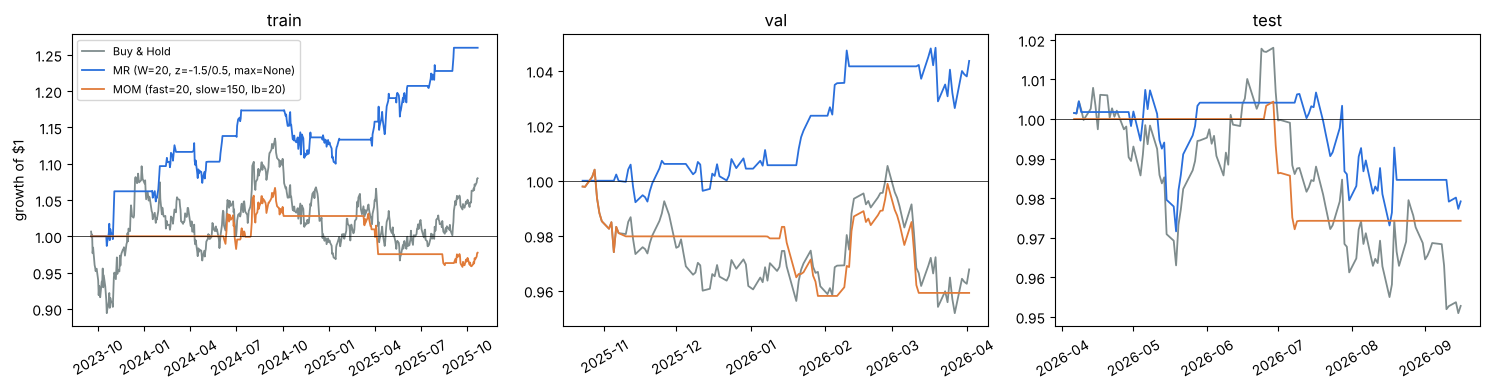

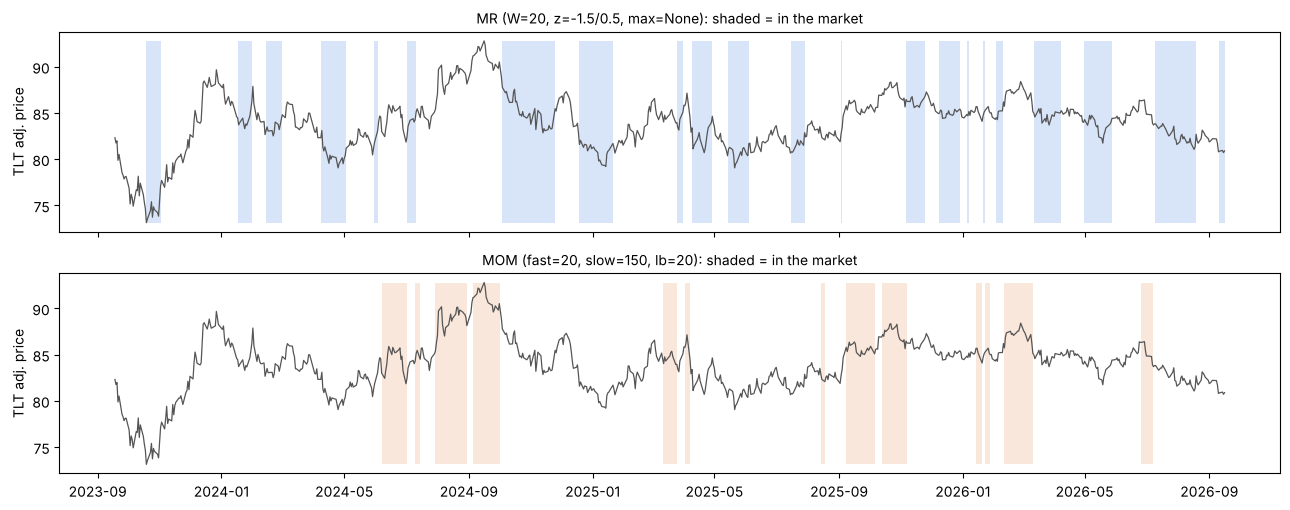

In [13]:
COL = {"Buy & Hold": "#7f8c8d"}
palette = ["#2a6fdb", "#e07b39"]
for i, name in enumerate([n for n in final if n != "Buy & Hold"]):
    COL[name] = palette[i]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, p in zip(axes, ("train", "val", "test")):
    for name in final:
        eq = res[(name, p)].equity
        ax.plot(eq.index, eq / INITIAL_CASH, lw=1.3, color=COL[name], label=name)
    ax.axhline(1, color="k", lw=0.5)
    ax.set_title(p)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("growth of $1")
axes[0].legend(fontsize=8, loc="best")
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_equity_by_period.png", dpi=130)
plt.show()

fig, axes = plt.subplots(len(final) - 1, 1, figsize=(13, 2.6 * (len(final) - 1)), sharex=True)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, [n for n in final if n != "Buy & Hold"]):
    ax.plot(tlt.index, tlt["close"], color="#555", lw=0.9)
    held = final[name] > 0
    ax.fill_between(tlt.index, tlt["close"].min(), tlt["close"].max(), where=held,
                    color=COL[name], alpha=0.18, step="pre", lw=0)
    ax.set_title(f"{name}: shaded = in the market", fontsize=10)
    ax.set_ylabel("TLT adj. price")
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_positions.png", dpi=130)
plt.show()

## 9. Save outputs

In [14]:
grid_df.drop(columns="params").to_csv(RESULTS_DIR / f"{TAG}_param_grid_train.csv", index=False)
shortlist.drop(columns="params").to_csv(RESULTS_DIR / f"{TAG}_shortlist_val.csv", index=False)
table.to_csv(RESULTS_DIR / f"{TAG}_metrics_test.csv")
summary.to_csv(RESULTS_DIR / f"{TAG}_metrics_by_period.csv")
diag.to_csv(RESULTS_DIR / f"{TAG}_diagnostics.csv")
for name, pos in final.items():
    if name != "Buy & Hold":
        trades = res[(name, "test")].trades
        trades.to_csv(RESULTS_DIR / f"{TAG}_{name.split()[0].lower()}_trades_test.csv", index=False)
for f in sorted(RESULTS_DIR.glob(f"{TAG}_*")):
    print("  ", f.name)

   tlt_diagnostics.csv
   tlt_equity_by_period.png
   tlt_metrics_by_period.csv
   tlt_metrics_test.csv
   tlt_mom_trades_test.csv
   tlt_mr_trades_test.csv
   tlt_param_grid_train.csv
   tlt_param_heatmaps.png
   tlt_positions.png
   tlt_shortlist_val.csv
